## Lab 14: EM Algorithm for Gausssian Mixture Models

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

## Q1. Generate 300 observations from three normal groups (means 2, 7, 12; sd 1)

In [2]:
np.random.seed(42)
group1 = np.random.normal(2, 1, 100)
group2 = np.random.normal(7, 1, 100)
group3 = np.random.normal(12, 1, 100)

data = np.concatenate([group1, group2, group3])
X = data.reshape(-1, 1)          # sklearn needs shape (n_samples, n_features)
print("Total observations:", len(X))

Total observations: 300


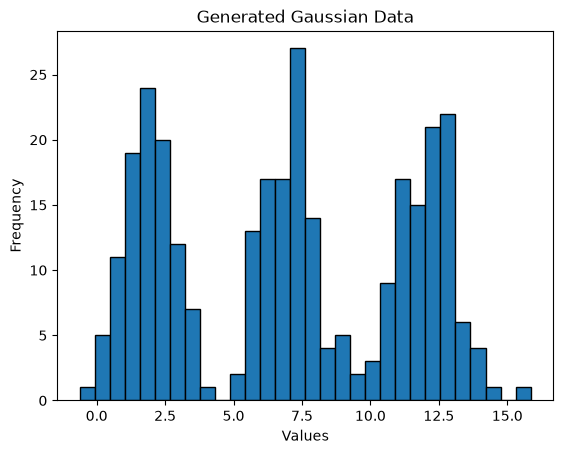

In [3]:
plt.hist(X, bins=30, edgecolor="black")
plt.title("Generated Gaussian Data")
plt.xlabel("Values"); plt.ylabel("Frequency")
plt.show()

**Interpretation:** the histogram shows three separate peaks near 2, 7 and 12, matching the three normal groups. The groups are standard deviations apart, so there is almost no overlap.

## Q2. Fit a GMM (EM algorithm) and find the groups

In [4]:
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)                       # runs EM: E-step, M-step, repeated until convergence
labels = gmm.predict(X)
print(labels[:20])
print("Converged:", gmm.converged_, "| EM iterations:", gmm.n_iter_)

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
Converged: True | EM iterations: 2


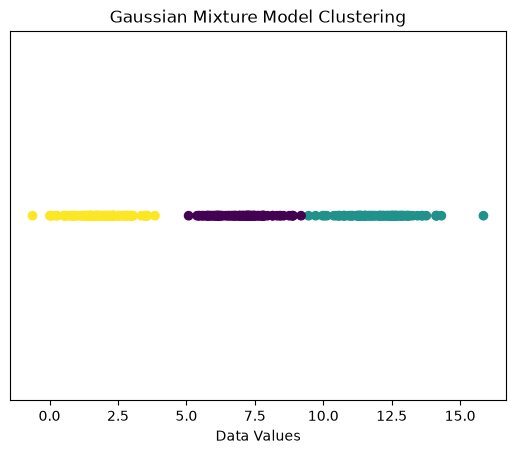

In [5]:
plt.scatter(X[:, 0], np.zeros(len(X)), c=labels, cmap="viridis")
plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Data Values"); plt.yticks([])
plt.show()

**Interpretation**: three clusters appear. The labels 0, 1, 2 are only names; GMM does not rank groups, and which cluster gets which number can change with the seed.

## Q3. Estimated means, variances and mixing proportions

In [6]:
print("Estimated Means:")
print(gmm.means_)
print("\nEstimated Variances:")
print(gmm.covariances_)
print("\nMixing Proportions:")
print(gmm.weights_)

Estimated Means:
[[ 6.98734645]
 [12.04041718]
 [ 1.89614955]]

Estimated Variances:
[[[0.8221013 ]]

 [[1.19793122]]

 [[0.81819915]]]

Mixing Proportions:
[0.32957963 0.33717043 0.33324994]


**interpretation**: the means are about 1.90, 6.99 and 12.04 (true values 2, 7, 12), the variances are roughly 0.8 to 1.2 (the true value is 1, since sd = 1; a sample of 100 per group varies a bit), and each weight is close to 1/3 (100 of 300 observations per group). Small differences are due to random sampling.

## Q4. BIC for 1 to 4 components

Components: 1 | BIC: 1733.11
Components: 2 | BIC: 1655.28
Components: 3 | BIC: 1526.83
Components: 4 | BIC: 1545.74


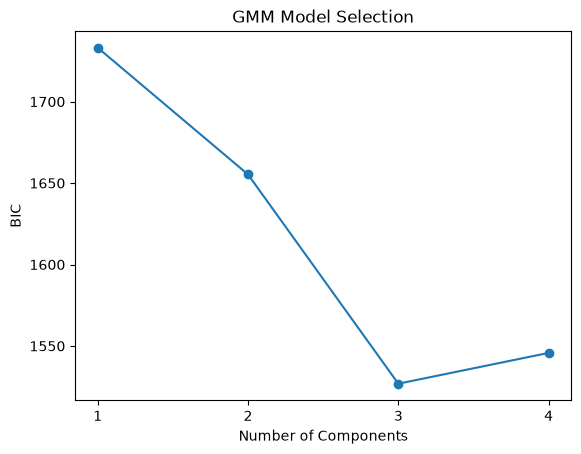

Best number of components (lowest BIC): 3


In [7]:
components = [1, 2, 3, 4]
bic_values = []
for k in components:
    model = GaussianMixture(n_components=k, random_state=42)
    model.fit(X)
    bic = model.bic(X)
    bic_values.append(bic)
    print("Components:", k, "| BIC:", round(bic, 2))

plt.plot(components, bic_values, marker="o")
plt.xlabel("Number of Components"); plt.ylabel("BIC")
plt.title("GMM Model Selection")
plt.xticks(components)
plt.show()
print("Best number of components (lowest BIC):", components[int(np.argmin(bic_values))])

**interpretation**: BIC drops sharply from 1 to 3 components and then stops improving (or rises) at 4, because the extra parameters are penalised. So 3 components is the best model, as expected.

## Lab 14 Assessment Questions
1. **EM algorithm:** an iterative method for estimating model parameters when some information is hidden or missing (e.g. which group each observation came from). It alternates an E-step and an M-step until the estimates stabilise.
2. **Gaussian Mixture Model:** a model that assumes the data come from a mixture of two or more normal distributions, each with its own mean, variance and mixing proportion.
3. **E-step vs M-step:** the E-step computes, for each observation, the probability that it belongs to each group using the current parameters. The M-step updates the means, variances and weights using those probabilities.
4. **Why clustering matters:** it finds hidden structure in unlabelled data (e.g. customer segments, crop zones) and supports summarising, prediction and decision making.
5. **`n_components`:** the number of Gaussian distributions (clusters) the model should fit.
6. **BIC:** compares models by balancing goodness of fit against complexity (number of parameters). Lower BIC is preferred, so it helps avoid overfitting when choosing the number of clusters.
7. **`fit()`:** runs the EM algorithm on the data and estimates the means, covariances and weights.
8. **Applications:** customer segmentation; image segmentation; speaker/voice recognition; anomaly (fraud) detection; grouping crop yields or soil types.

# Lab 15: Neural Network with PyTorch Autograd


In [8]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

data = torch.tensor([2.0, 4.0, 6.0, 8.0, 10.0])
print(data)

tensor([ 2.,  4.,  6.,  8., 10.])


A **tensor** is a multidimensional array like a NumPy array, but it can track operations for automatic differentiation and run on a GPU.

## Q2. Autograd: y = x² + 3x + 2 at x = 5


In [9]:
x = torch.tensor(5.0, requires_grad=True)   # track operations on x
y = x**2 + 3*x + 2
print(y)          # tensor(42., grad_fn=<AddBackward0>)

y.backward()      # computes dy/dx
print(x.grad)     # tensor(13.)

tensor(42., grad_fn=<AddBackward0>)
tensor(13.)


## Q3. Train a neural network to learn y = 2x + 1


In [10]:
torch.manual_seed(42)
X = torch.linspace(0, 10, 100).reshape(-1, 1)
Y = 2*X + 1

class SimpleNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(1, 1)     # 1 input, 1 output: y = w*x + b
    def forward(self, x):
        return self.layer(x)

model = SimpleNN()
print(model)

loss_function = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

SimpleNN(
  (layer): Linear(in_features=1, out_features=1, bias=True)
)


In [11]:
for epoch in range(1000):
    predictions = model(X)
    loss = loss_function(predictions, Y)

    optimizer.zero_grad()    # clear old gradients (must be INSIDE the loop)
    loss.backward()          # compute new gradients
    optimizer.step()         # update w and b

    if (epoch + 1) % 100 == 0:
        print(epoch + 1, loss.item())

100 2.2541780708706938e-05
200 8.332306606462225e-06
300 3.0789271932007978e-06
400 1.1383613127691206e-06
500 4.2087137330781843e-07
600 1.5562085309284157e-07
700 5.751731180225761e-08
800 2.1246087555937265e-08
900 7.904436216676913e-09
1000 2.8960116527088076e-09


In [12]:
test_data = torch.tensor([[5.0]])
prediction = model(test_data)
print("Prediction:", prediction.item())      # should be close to 11
print("Learned weight:", model.layer.weight.item(), "| bias:", model.layer.bias.item())

Prediction: 11.000025749206543
Learned weight: 1.9999840259552002 | bias: 1.0001062154769897


The true value is 2(5) + 1 = 11. The learned weight should be close to 2 and the bias close to 1.

## Q4. Actual data vs predictions


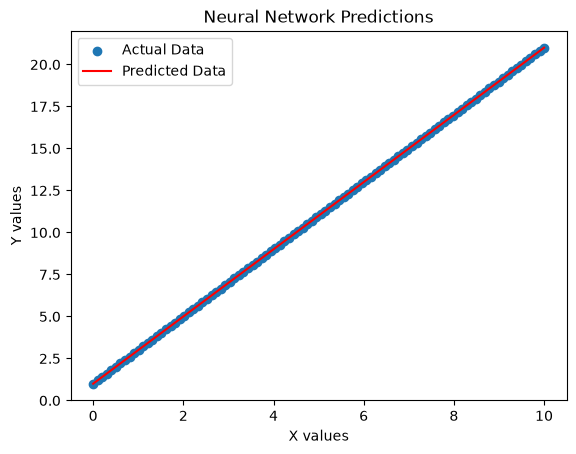

In [13]:
with torch.no_grad():
    predicted_values = model(X)

plt.scatter(X.numpy(), Y.numpy(), label="Actual Data")
plt.plot(X.numpy(), predicted_values.numpy(), color="red", label="Predicted Data")
plt.xlabel("X values"); plt.ylabel("Y values")
plt.title("Neural Network Predictions")
plt.legend()
plt.show()

**Interpretation:** the red line passes through the points, so the network has learned the relationship y = 2x + 1.

## Lab 15 Assessment Questions
1. **Neural network:** a machine-learning model of interconnected neurons arranged in layers (input, hidden, output) that learns patterns from data.
2. **PyTorch:** a Python library for building and training machine-learning and deep-learning models.
3. **Autograd:** PyTorch's automatic differentiation; it records operations and computes gradients for you.
4. **Tensor:** a multidimensional array of numbers that supports gradient tracking and GPU computation.
5. **Loss function:** measures how far predictions are from actual values; training tries to minimise it (e.g. MSE).
6. **Gradient descent:** repeatedly moves parameters in the direction that reduces the loss, using the gradient, so the model improves step by step.
7. **`backward()`:** computes the gradient of the loss with respect to every parameter with `requires_grad=True`.
8. **Optimizer:** updates the parameters using the gradients (e.g. SGD, Adam).
9. **Training vs testing data:** training data is used to fit the model; testing data is unseen data used to check how well it generalises.
10. **Applications:** house price prediction; handwritten digit recognition; customer behaviour prediction; classifying agricultural products; medical diagnosis.

## Lab 16 Notebook hygiene, Reproducibility and packaging

# Q1. Reproducible maize dataset

In [1]:
import numpy as np

np.random.seed(123)       # same seed -> same random numbers every run
maize = np.random.normal(loc=5, scale=1.2, size=100)

print("Mean:", np.mean(maize))
print("Standard deviation:", np.std(maize))
print("Maximum:", np.max(maize))

Mean: 5.032530888188432
Standard deviation: 1.3538885645735532
Maximum: 7.870838319125271


**Interpretation**:The programme calculates the average maize production, the variation in production and the highest recorded observation.

## Lab 16 Assessment Questions
1. **Reproducibility:** another researcher can use the same data, code and instructions and obtain the same (or sufficiently similar) results.
2. **Notebook hygiene:** keeping notebooks clean, organised and readable: title, introduction, sections, explained code, outputs, interpretations, conclusions and references.
3. **Random seeds:** fix the starting point of the random number generator so the same "random" numbers are generated each run.
4. **nbconvert:** a Jupyter tool that converts notebooks into other formats.
5. **Formats:** HTML, PDF, Python script (also Markdown, LaTeX).
6. **README:** explains what the project is, how to install it and how to run it.
7. **requirements.txt:** lists the Python libraries needed so others can install them with `pip install -r requirements.txt`.
8. **Why organise files:** others can find, run and check the work; it prevents errors and saves time.
9. **CSV:** Comma-Separated Values, a simple text format for tabular data.
10. **Importance of reproducible research:** results can be verified and trusted, errors are easier to find, work can be reused and built upon, and it supports scientific integrity.

## Lab 17: interactive Statistical Dashboard with streamlit

# Q1.Install and check

In [4]:
!pip install streamlit
!pip install pandas numpy matplotlib

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
    --------------------------------------- 0.3/11.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.2 MB 837.5 kB/s eta 0:00:13
   -- ------------------------------------- 0.8/11.2 MB 882.6 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/11.2 MB 882.6 kB/s eta 0:00:12
   --- ------------------------------------ 1.0/11.2 MB 931.8 kB/s eta 0:00:11
   ---- ----------------------------------- 1.3/11.2 MB 958.5 kB/s eta 0:00:11
   ----- ---------------------------------- 1.6/11.2 MB 911.5 kB/s eta 0:00:11
   ------ --------------------------------- 1.8/11.2 MB 949.8 kB/s eta 0:00:10
   ------ -----------------

In [7]:
!streamlit --version

Streamlit, version 1.67.0


In [8]:
import pandas as pd
data = {
    "District": ["Lusaka", "Chongwe", "Kabwe", "Chipata", "Mumbwa"],
    "Production": [500, 350, 450, 600, 400],
}
df17 = pd.DataFrame(data)
print(df17)
print("Total:", df17["Production"].sum(), "| Average:", df17["Production"].mean())

  District  Production
0   Lusaka         500
1  Chongwe         350
2    Kabwe         450
3  Chipata         600
4   Mumbwa         400
Total: 2300 | Average: 460.0


# Q3 and Q4. The dashboard 

## Lab 17 Assessment Questions
1. **Dashboard:** an interactive visual display that shows key information using graphs, tables and numerical summaries.
2. **Streamlit:** a Python framework for building interactive web apps and dashboards without web-development skills.
3. **Panel:** another Python framework for interactive dashboards and data apps; more flexible and customisable than Streamlit.
4. **Advantages:** results are understood quickly; users can interact with the data; findings are easy to share; several outputs are shown in one place.
5. **`st.title()`:** displays the title at the top of the app.
6. **`st.dataframe()`:** displays a DataFrame as an interactive table.
7. **`selectbox()`:** creates a dropdown so the user can pick one option, and the app updates to match.
8. **Data visualisation:** presenting data as graphs, charts or maps to reveal patterns and make results easier to understand.
9. **Static graph vs dashboard:** a static graph is a fixed image; a dashboard is interactive and lets users select, filter and explore.
10. **Applications:** monitoring crop production by district; displaying survey results; tracking model performance or simulation output.